# Open e-commerce 1.0: what 5,027 Amazon users bought, when, and who spent
# Open e-commerce 1.0: 5,027 Amazon istifadəçisi nə aldı, nə vaxt aldı və kim nə qədər xərclədi

**Data / Məlumat:** Open e-commerce 1.0, 5,027 US Amazon users, 1,850,717 item rows, January 2018 to late 2022.
Files / Fayllar: `amazon-purchases.csv`, `survey.csv`, `fields.csv`. Harvard Dataverse, DOI [10.7910/DVN/YGLYDY](https://doi.org/10.7910/DVN/YGLYDY). Join key / birləşdirmə açarı: `Survey ResponseID`.

**Cite / İstinad:** Berke, A. et al. *Sci Data* **11**, 491 (2024). https://doi.org/10.1038/s41597-024-03329-6. **License / Lisenziya:** CC BY 4.0.

**Stack:** pandas, numpy, matplotlib only (no seaborn). / Yalnız pandas, numpy, matplotlib (seaborn yoxdur).

**en:** Seven sections: setup, data quality, spend distribution, what people buy, seasonality, who spends, geography. Every plot has a title, axis labels and a one-line interpretation printed under it (computed from the data, in English and Azerbaijani).

**az:** Yeddi bölmə: yükləmə, data keyfiyyəti, xərc paylanması, nə alınır, mövsümilik, kim xərcləyir, coğrafiya. Hər qrafikin başlığı, oxlarının adları və altında məlumatdan hesablanmış, ingiliscə və azərbaycanca bir sətirlik şərh var.

## 1. Setup and load / Yükləmə

**en:** Import the three libraries, load the three CSVs, print shape, dtypes and samples. `fields.csv` is used only as a lookup so survey column names are not guessed. If the CSVs are not in `DATA_DIR`, the cell downloads them from Harvard Dataverse (the purchases file is large). Then `Order date` is parsed to datetime and `line_total = price * quantity` becomes the working spend column.

**az:** Üç kitabxananı import edirik, üç CSV faylını yükləyirik, forma, tip və nümunələri çap edirik. `fields.csv` yalnız axtarış cədvəli kimi istifadə olunur ki, sorğu sütun adları təxmin edilməsin. CSV-lər `DATA_DIR`-də yoxdursa, xana onları Harvard Dataverse-dən endirir (alışlar faylı böyükdür). Sonra `Order date` datetime-a çevrilir və `line_total = price * quantity` əsas xərc sütunu olur.

In [5]:
import os, shutil, json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})
C1, C2, C3 = "#2f6db5", "#e07b39", "#7a7a7a"   # one main colour, one accent, one neutral

def interp(en, az):
    """One-line interpretation printed under a plot, in both languages."""
    print("Interpretation (en):", en)
    print("Şərh (az):          ", az)

# Column names exactly as they appear in the released CSV
ID, DATE, STATE = "Survey ResponseID", "Order Date", "Shipping Address State"
PRICE, QTY, ASIN = "Purchase Price Per Unit", "Quantity", "ASIN/ISBN (Product Code)"
TITLE, CAT = "Title", "Category"

DATA_DIR = os.environ.get("OPEN_ECOMMERCE_DIR", "data/open-ecommerce")   # local copy of the dataset
DOI = "doi:10.7910/DVN/YGLYDY"
os.makedirs(DATA_DIR, exist_ok=True)

# Harvard Dataverse answers 403 to urllib's default "Python-urllib" User-Agent
HEADERS = {"User-Agent": "Mozilla/5.0 (open-ecommerce-notebook)"}

def _open(url):
    return urllib.request.urlopen(urllib.request.Request(url, headers=HEADERS))

def ensure_file(name):
    path = os.path.join(DATA_DIR, name)
    if os.path.exists(path) and os.path.getsize(path) > 0:
        print(f"using local file: {path}")   # no network access when the file is already on disk
        return path
    meta_url = f"https://dataverse.harvard.edu/api/datasets/:persistentId/?persistentId={DOI}"
    with _open(meta_url) as r:
        files = json.load(r)["data"]["latestVersion"]["files"]
    fid = next(f["dataFile"]["id"] for f in files if f["dataFile"]["filename"].rsplit(".", 1)[0] == name.rsplit(".", 1)[0])
    print("downloading", name, "...")
    tmp = path + ".part"
    with _open(f"https://dataverse.harvard.edu/api/access/datafile/{fid}?format=original") as r, open(tmp, "wb") as out:
        shutil.copyfileobj(r, out)
    os.replace(tmp, path)  # no half-downloaded file is left behind on failure
    return path

purchases_raw = pd.read_csv(ensure_file("amazon-purchases.csv"), low_memory=False)
survey = pd.read_csv(ensure_file("survey.csv"), low_memory=False)
fields = pd.read_csv(ensure_file("fields.csv"), index_col=0)

for name, d in [("amazon-purchases", purchases_raw), ("survey", survey), ("fields", fields)]:
    print(f"\n=== {name}: shape {d.shape}")
    print(d.dtypes.to_string())
print("\n--- purchases sample"); display(purchases_raw.sample(5, random_state=0))
print("--- survey sample");     display(survey.sample(5, random_state=0).iloc[:, :12])

using local file: data/open-ecommerce/amazon-purchases.csv
using local file: data/open-ecommerce/survey.csv
using local file: data/open-ecommerce/fields.csv

=== amazon-purchases: shape (1850717, 8)
Order Date                   object
Purchase Price Per Unit     float64
Quantity                    float64
Shipping Address State       object
Title                        object
ASIN/ISBN (Product Code)     object
Category                     object
Survey ResponseID            object

=== survey: shape (5027, 23)
Survey ResponseID             object
Q-demos-age                   object
Q-demos-hispanic              object
Q-demos-race                  object
Q-demos-education             object
Q-demos-income                object
Q-demos-gender                object
Q-sexual-orientation          object
Q-demos-state                 object
Q-amazon-use-howmany          object
Q-amazon-use-hh-size          object
Q-amazon-use-how-oft          object
Q-substance-use-cigarettes    object
Q-

,Order Date,Purchase Price Per Unit,Quantity,Shipping Address State,Title,ASIN/ISBN (Product Code),Category,Survey ResponseID
642303,2021-03-20,26.99,1.0,NY,Essential Gel Boxing Kickboxing Punching Bag G...,B01I3Q3176,BOXING_GLOVE,R_2S31vSPrwOLWHLA
78672,2022-05-11,13.99,1.0,IL,The Last Unicorn (Cover print may vary),0451450523,ABIS_BOOK,R_1DYWdbAMt6LyCZH
191557,2021-10-19,29.99,1.0,NY,ILHWA Fermented Panax Korean Ginseng Liquid Ex...,B01MQP1A3M,HERBAL_SUPPLEMENT,R_1NlGZCWpxXc8mjn
1745237,2020-06-07,19.77,1.0,VA,INFINITIPRO BY CONAIR Tourmaline 1 1/2-Inch Ce...,B000F5AG5E,HAIR_IRON,R_r1oTDkv1OlGnNuN
1625722,2019-02-22,17.25,2.0,DE,Fresh Step Multi-Cat Scented Litter with the P...,B0784SX6XX,ANIMAL_LITTER,R_Xhz81T9LodPX0KB


--- survey sample


,Survey ResponseID,Q-demos-age,Q-demos-hispanic,Q-demos-race,Q-demos-education,Q-demos-income,Q-demos-gender,Q-sexual-orientation,Q-demos-state,Q-amazon-use-howmany,Q-amazon-use-hh-size,Q-amazon-use-how-oft
2817,R_2rOPRiLTdvFrJFq,18 - 24 years,No,White or Caucasian,Bachelor's degree,"$25,000 - $49,999",Male,LGBTQ+,California,2,3,5 - 10 times per month
1662,R_7UtikIBqeQHvnyN,25 - 34 years,No,Black or African American,High school diploma or GED,"Less than $25,000",Female,LGBTQ+,Alabama,1 (just me!),2,Less than 5 times per month
4567,R_2w5nlHIgm7y2g6p,25 - 34 years,No,White or Caucasian,High school diploma or GED,"$100,000 - $149,999",Male,LGBTQ+,California,1 (just me!),3,Less than 5 times per month
3651,R_339iXVPjwR19zGl,18 - 24 years,No,White or Caucasian,Bachelor's degree,"$50,000 - $74,999",Male,LGBTQ+,Colorado,1 (just me!),3,Less than 5 times per month
2905,R_1i2QZkwVzyMHerI,45 - 54 years,No,Black or African American,Bachelor's degree,"$150,000 or more",Male,heterosexual (straight),North Carolina,1 (just me!),3,Less than 5 times per month


In [6]:
# fields.csv as a lookup: survey column -> question text (no guessing of names)
fields_lookup = fields.iloc[:, 0].to_dict()
DEMO = ["Q-demos-age", "Q-demos-income", "Q-demos-education", "Q-demos-gender", "Q-demos-state"]
for c in DEMO:
    assert c in survey.columns, f"{c} not in survey.csv"
    print(f"{c:20s} -> {str(fields_lookup.get(c))[:90]!r}")
assert survey[ID].is_unique, "survey should have one row per respondent"

Q-demos-age          -> 'What is your age group?'
Q-demos-income       -> 'What was your total household income before taxes during the past 12 months?'
Q-demos-education    -> 'What is the highest level of education you have completed?'
Q-demos-gender       -> 'How do you describe yourself?'
Q-demos-state        -> '50 States, D.C. and Puerto Rico'


In [7]:
# Parse dates, coerce numbers, build the working spend column.
def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")

na_before = {PRICE: purchases_raw[PRICE].isna().sum(), QTY: purchases_raw[QTY].isna().sum()}
purchases_raw[DATE] = pd.to_datetime(purchases_raw[DATE], errors="coerce")
purchases_raw[PRICE] = to_num(purchases_raw[PRICE])
purchases_raw[QTY] = to_num(purchases_raw[QTY])
purchases_raw["line_total"] = purchases_raw[PRICE] * purchases_raw[QTY]

print("unparseable dates:", purchases_raw[DATE].isna().sum())
print("date range:", purchases_raw[DATE].min().date(), "->", purchases_raw[DATE].max().date())
print("rows:", f"{len(purchases_raw):,}", "| users:", f"{purchases_raw[ID].nunique():,}")

unparseable dates: 0
date range: 2018-01-01 -> 2024-08-15
rows: 1,850,717 | users: 5,027


**Grain / Dənə səviyyəsi — en:** one row is **one purchased item, not one order**. There is no order id, so "orders" below always means item rows (or units).

**az:** Bir sətir **bir alınmış məhsuldur, bir sifariş deyil**. Sifariş identifikatoru yoxdur; ona görə aşağıda "sifariş" dedikdə məhsul sətirləri (və ya ədədlər) nəzərdə tutulur.

## 2. Data quality and cleanup / Data keyfiyyəti və təmizləmə

**en:** Judgment over `dropna`. Missing title, category or state is expected for digital goods, gift cards and Amazon Lockers, so those rows are **flagged, not dropped**. Steps: missingness table, numeric coercion checks, state mapping with an explicit unmapped bucket, gift-card flag, date window (1 Jan 2018 to 31 Oct 2022, to avoid export censoring looking like a demand crash), outliers (winsorize at p99 for plots only), residual duplicates, then an inner join to the survey.

**az:** `dropna` əvəzinə mühakimə. Rəqəmsal məhsullar, hədiyyə kartları və Amazon Locker üçün çatışmayan başlıq, kateqoriya və ya ştat gözləniləndir; bu sətirlər **işarələnir, silinmir**. Addımlar: çatışmazlıq cədvəli, rəqəmə çevirmə yoxlamaları, açıq "xəritələnməyən" qrupu ilə ştat xəritələnməsi, hədiyyə kartı işarəsi, tarix pəncərəsi (2018-01-01 – 2022-10-31; 2022-nin sonunda ixrac kəsilməsi tələb düşməsi kimi görünməsin), kənar qiymətlər (yalnız qrafiklər üçün p99-da winsorize), qalıq dublikatlar, sonra survey ilə inner join.

In [8]:
# 2a. Missingness (on the file as loaded, before any row is removed)
check_cols = [TITLE, CAT, STATE, PRICE, QTY, ASIN]
miss = pd.DataFrame({"missing_n": purchases_raw[check_cols].isna().sum(),
                     "missing_%": (purchases_raw[check_cols].isna().mean() * 100).round(2)})
display(miss)

df = purchases_raw.copy()
df["miss_title"], df["miss_cat"], df["miss_state"] = df[TITLE].isna(), df[CAT].isna(), df[STATE].isna()
print("Rows missing at least one of title/category/state (flagged, kept):",
      f"{(df.miss_title | df.miss_cat | df.miss_state).sum():,}")

,missing_n,missing_%
Title,89740,4.85
Category,89458,4.83
Shipping Address State,87812,4.74
Purchase Price Per Unit,0,0.00
Quantity,0,0.00
ASIN/ISBN (Product Code),973,0.05


Rows missing at least one of title/category/state (flagged, kept): 175,422


In [9]:
# 2b. Price and quantity
print("Newly NaN after numeric coercion -> price:", int(df[PRICE].isna().sum() - na_before[PRICE]),
      "| quantity:", int(df[QTY].isna().sum() - na_before[QTY]))
print("price null:", df[PRICE].isna().sum(), "| price <= 0:", (df[PRICE] <= 0).sum(),
      "| quantity null:", df[QTY].isna().sum(), "| quantity == 0:", (df[QTY] == 0).sum(),
      "| quantity < 0:", (df[QTY] < 0).sum())

# Spend is undefined (NaN) for these rows; they stay in the frame, flagged.
df["bad_spend"] = ~((df[PRICE] > 0) & (df[QTY] > 0))
df.loc[df.bad_spend, "line_total"] = np.nan
print("rows with undefined spend (flagged, kept):", f"{df.bad_spend.sum():,}")

Newly NaN after numeric coercion -> price: 0 | quantity: 0
price null: 0 | price <= 0: 0 | quantity null: 0 | quantity == 0: 0 | quantity < 0: 0
rows with undefined spend (flagged, kept): 0


In [10]:
# 2c. Shipping state -> two-letter code. Never invent a state.
US = {"Alabama":"AL","Alaska":"AK","Arizona":"AZ","Arkansas":"AR","California":"CA","Colorado":"CO","Connecticut":"CT",
 "Delaware":"DE","District of Columbia":"DC","Florida":"FL","Georgia":"GA","Hawaii":"HI","Idaho":"ID","Illinois":"IL",
 "Indiana":"IN","Iowa":"IA","Kansas":"KS","Kentucky":"KY","Louisiana":"LA","Maine":"ME","Maryland":"MD","Massachusetts":"MA",
 "Michigan":"MI","Minnesota":"MN","Mississippi":"MS","Missouri":"MO","Montana":"MT","Nebraska":"NE","Nevada":"NV",
 "New Hampshire":"NH","New Jersey":"NJ","New Mexico":"NM","New York":"NY","North Carolina":"NC","North Dakota":"ND",
 "Ohio":"OH","Oklahoma":"OK","Oregon":"OR","Pennsylvania":"PA","Rhode Island":"RI","South Carolina":"SC","South Dakota":"SD",
 "Tennessee":"TN","Texas":"TX","Utah":"UT","Vermont":"VT","Virginia":"VA","Washington":"WA","West Virginia":"WV",
 "Wisconsin":"WI","Wyoming":"WY","Puerto Rico":"PR"}
NAME2CODE = {k.upper(): v for k, v in US.items()}
VALID_CODES = set(US.values())

def map_state(s):
    t = s.astype("string").str.strip().str.upper()
    out = t.where(t.isin(VALID_CODES), t.map(NAME2CODE))
    out = out.fillna("UNMAPPED")
    return out.where(t.notna(), "MISSING")      # genuinely absent stays MISSING

df["state_code"] = map_state(df[STATE])
print(df.state_code.map(lambda x: x if x in ("MISSING", "UNMAPPED") else "mapped").value_counts().to_string())
print("\nUnmapped raw values (top 25):")
print(df.loc[df.state_code == "UNMAPPED", STATE].value_counts().head(25).to_string())

state_code
mapped     1762905
MISSING      87812

Unmapped raw values (top 25):
Series([], )


In [11]:
# 2d. Gift cards: flagged on title OR category, kept in the raw frame.
gc_pat = r"gift[ _-]?card"
df["is_gift_card"] = (df[TITLE].str.contains(gc_pat, case=False, regex=True, na=False)
                      | df[CAT].str.contains(gc_pat, case=False, regex=True, na=False))
gc = df[df.is_gift_card]
print(f"gift-card rows: {len(gc):,} from {gc[ID].nunique():,} users   (paper: 40,368 rows, 3,220 users)")
print("price quantiles of gift-card rows:", np.nanpercentile(gc[PRICE], [0, 5, 50, 95, 100]).round(2))
per_user = gc.groupby(ID).size()
print("top 1% of gift-card users have more than", int(np.percentile(per_user, 99)), "gift-card rows each   (paper: >167)")

gift-card rows: 41,476 from 3,125 users   (paper: 40,368 rows, 3,220 users)
price quantiles of gift-card rows: [5.e-01 5.e-01 2.e+01 1.e+02 2.e+03]
top 1% of gift-card users have more than 167 gift-card rows each   (paper: >167)


In [12]:
# 2e. Date window, then split gift cards out, then join survey.
START, END_EXCL = pd.Timestamp("2018-01-01"), pd.Timestamp("2022-11-01")
n_raw = len(df)
no_date = df[DATE].isna().sum()
in_win = (df[DATE] >= START) & (df[DATE] < END_EXCL)
print(f"dropped by window: {(~in_win).sum():,}  (of which unparseable date: {no_date:,}; after 31 Oct 2022: {(df[DATE] >= END_EXCL).sum():,}; before 2018: {(df[DATE] < START).sum():,})")
win = df[in_win].copy()
win["month"] = win[DATE].dt.to_period("M").dt.to_timestamp()
win["year"], win["moy"] = win[DATE].dt.year, win[DATE].dt.month
win["cat"] = win[CAT].fillna("(missing)")

purchases_gc = win[win.is_gift_card].copy()          # kept for one later chart
nogc = win[~win.is_gift_card].copy()
print(f"gift-card rows moved to purchases_gc: {len(purchases_gc):,}")

SURVEY_COLS = [ID] + DEMO                            # race and health fields deliberately left out
m = nogc.merge(survey[SURVEY_COLS], on=ID, how="left", indicator=True)
print(f"purchases with no survey row: {(m._merge == 'left_only').sum():,} (dropped by the inner join; no demographics imputed)")
purchases = m[m._merge == "both"].drop(columns="_merge").reset_index(drop=True)
print("analysis frame 'purchases':", f"{len(purchases):,} rows,", f"{purchases[ID].nunique():,} users")

dropped by window: 113,659  (of which unparseable date: 0; after 31 Oct 2022: 113,659; before 2018: 0)
gift-card rows moved to purchases_gc: 38,850
purchases with no survey row: 0 (dropped by the inner join; no demographics imputed)
analysis frame 'purchases': 1,698,208 rows, 5,014 users


In [13]:
# 2f. Outliers: do not delete high spend. Winsorize at p99 for plots only.
p50, p95, p99, pmax = np.nanpercentile(purchases.line_total, [50, 95, 99, 100])
print(f"line_total  p50={p50:,.2f}  p95={p95:,.2f}  p99={p99:,.2f}  max={pmax:,.2f}")
purchases["line_total_w"] = purchases.line_total.clip(upper=p99)

# 2g. Residual duplicates (authors already removed exact duplicates; confirm, do not remove)
dup_cols = [ID, DATE, ASIN, PRICE, QTY, STATE, TITLE]
dup_rate = purchases.duplicated(subset=dup_cols, keep="first").mean()
print(f"residual duplicate rate on {len(dup_cols)} key columns: {dup_rate:.3%} (kept: identical items bought twice in a day are plausible)")

line_total  p50=14.49  p95=63.00  p99=179.99  max=6,398.95
residual duplicate rate on 7 key columns: 0.293% (kept: identical items bought twice in a day are plausible)


In [14]:
audit = pd.DataFrame([
    ("raw rows loaded",                              n_raw),
    ("- outside 2018-01-01..2022-10-31 (or no date)", -(~in_win).sum()),
    ("- gift cards (moved to purchases_gc)",          -len(purchases_gc)),
    ("- no matching survey row",                      -(m._merge == "left_only").sum()),
    ("= analysis frame 'purchases'",                  len(purchases)),
], columns=["step", "rows"])
audit["rows"] = audit.rows.map("{:,}".format)
display(audit)
print("Flagged but kept in analysis frame:",
      f"missing title {purchases[TITLE].isna().sum():,}, missing category {purchases[CAT].isna().sum():,},",
      f"missing state {(purchases.state_code == 'MISSING').sum():,}, unmapped state {(purchases.state_code == 'UNMAPPED').sum():,},",
      f"undefined spend {purchases.bad_spend.sum():,}")

,step,rows
0,raw rows loaded,"1,850,717"
1,- outside 2018-01-01..2022-10-31 (or no date),"-113,659"
2,- gift cards (moved to purchases_gc),"-38,850"
3,- no matching survey row,0
4,= analysis frame 'purchases',"1,698,208"


Flagged but kept in analysis frame: missing title 88,921, missing category 88,715, missing state 47,375, unmapped state 0, undefined spend 0


**Flagged vs dropped / İşarələnənlər və silinənlər — en:**
- **Dropped:** rows outside the date window, gift-card rows (moved to `purchases_gc`, still in `df`), rows without a survey match.
- **Flagged, kept:** missing title/category/state (digital goods, Lockers), unmapped states, non-positive price or zero quantity (spend set to NaN so sums ignore them), residual duplicates.
- **Never altered:** high spend. A winsorized column `line_total_w` exists for plots only.

**az:**
- **Silinənlər:** tarix pəncərəsindən kənar sətirlər, hədiyyə kartı sətirləri (`purchases_gc`-yə köçürülüb, `df`-də qalır), survey cavabı olmayan sətirlər.
- **İşarələnib saxlananlar:** çatışmayan başlıq/kateqoriya/ştat (rəqəmsal məhsullar, Locker), xəritələnməyən ştatlar, qeyri-müsbət qiymət və ya sıfır say (xərc NaN edilir, cəmlər onları nəzərə almır), qalıq dublikatlar.
- **Toxunulmayan:** yüksək xərc. Winsorize edilmiş `line_total_w` yalnız qrafiklər üçündür.

## 3. Spend distribution / Xərc paylanması

**en:** A user-level panel built with `groupby`: item rows, units, spend, active months, distinct ASINs and median line price. numpy gives log spend (`log1p`), percentile ranks and a Gini coefficient (Lorenz area by the trapezoid rule). Expect heavy skew, so **medians sit next to means from here on**.

**az:** `groupby` ilə istifadəçi səviyyəli cədvəl: məhsul sətirləri, ədəd, xərc, aktiv aylar, fərqli ASIN-lər və median qiymət. numpy ilə log xərc (`log1p`), faiz sıraları və Gini əmsalı (Lorenz sahəsi trapesiya qaydası ilə). Güclü əyrilik gözlənilir, ona görə **bundan sonra hər yerdə ortalamanın yanında median verilir**.

In [15]:
users = purchases.groupby(ID).agg(
    items=(DATE, "size"), units=(QTY, "sum"), spend=("line_total", "sum"),
    active_months=("month", "nunique"), distinct_asins=(ASIN, "nunique"),
    median_line_price=(PRICE, "median"), first_month=("month", "min"), last_month=("month", "max"))

spend = users.spend.to_numpy()
users["log_spend"] = np.log1p(spend)
rank = np.argsort(np.argsort(spend))
users["spend_pct_rank"] = rank / (len(spend) - 1) * 100

trapz = getattr(np, "trapezoid", None) or np.trapz
s_sorted = np.sort(spend)
cum = np.insert(np.cumsum(s_sorted), 0, 0.0)
lorenz = cum / cum[-1]
x_l = np.linspace(0, 1, len(lorenz))
gini = 1 - 2 * trapz(lorenz, x_l)
top1 = s_sorted[-int(np.ceil(0.01 * len(s_sorted))):].sum() / s_sorted.sum()
top10 = s_sorted[-int(np.ceil(0.10 * len(s_sorted))):].sum() / s_sorted.sum()

display(users.drop(columns=["log_spend", "spend_pct_rank", "first_month", "last_month"]).describe(percentiles=[.5, .9, .99]).round(1).T)
print(f"users: {len(users):,} | spend mean ${spend.mean():,.0f} vs median ${np.median(spend):,.0f}")
print(f"Gini = {gini:.3f} | top 1% of users = {top1:.1%} of spend | top 10% = {top10:.1%}")

,count,mean,std,min,50%,90%,99%,max
items,5014.0,338.7,397.9,1.0,209.5,799.1,1868.6,4869.0
units,5014.0,369.0,443.3,1.0,224.0,881.7,2125.6,5200.0
spend,5014.0,7988.6,9074.9,5.0,5166.2,18550.9,42852.9,106886.9
active_months,5014.0,37.1,17.1,1.0,40.0,58.0,58.0,58.0
distinct_asins,5014.0,288.3,321.9,0.0,189.0,662.7,1506.2,4025.0
median_line_price,5014.0,15.3,6.2,2.2,15.0,20.0,31.0,219.0


users: 5,014 | spend mean $7,989 vs median $5,166
Gini = 0.533 | top 1% of users = 7.1% of spend | top 10% = 36.6%


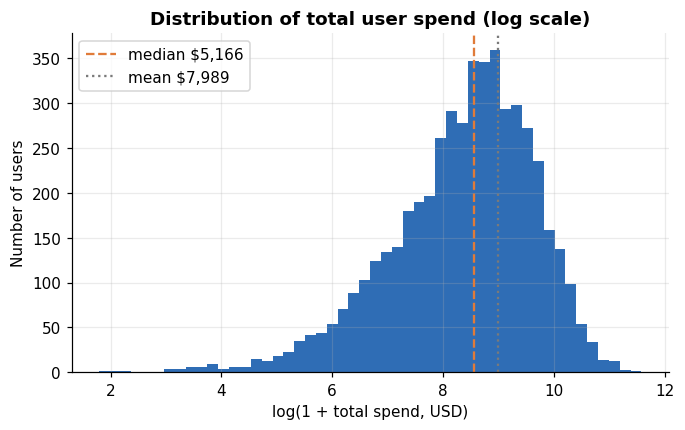

Interpretation (en): On a log axis the distribution is roughly bell-shaped, but the mean ($7,989) sits well above the median ($5,166).
Şərh (az):           Loqarifmik oxda paylanma təxminən zəng formasındadır, lakin ortalama ($7,989) mediandan ($5,166) xeyli yuxarıdır.


In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(users.log_spend, bins=50, color=C1)
ax.axvline(np.log1p(np.median(spend)), color=C2, ls="--", label=f"median ${np.median(spend):,.0f}")
ax.axvline(np.log1p(spend.mean()), color=C3, ls=":", label=f"mean ${spend.mean():,.0f}")
ax.set(title="Distribution of total user spend (log scale)", xlabel="log(1 + total spend, USD)", ylabel="Number of users")
ax.legend(); plt.show()
interp(f"On a log axis the distribution is roughly bell-shaped, but the mean (${spend.mean():,.0f}) sits well above the median (${np.median(spend):,.0f}).",
       f"Loqarifmik oxda paylanma təxminən zəng formasındadır, lakin ortalama (${spend.mean():,.0f}) mediandan (${np.median(spend):,.0f}) xeyli yuxarıdır.")

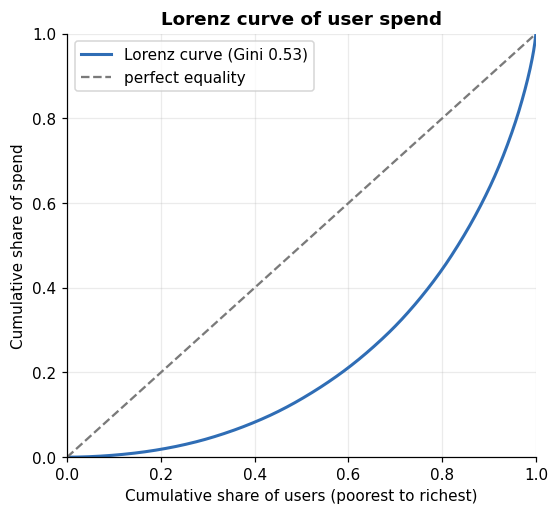

Interpretation (en): The top 1% of users account for 7.1% of spend and the top 10% for 36.6%; Gini is 0.53.
Şərh (az):           İstifadəçilərin ilk 1%-i xərcin 7.1%-ni, ilk 10%-i 36.6%-ni təşkil edir; Gini 0.53-dir.


In [17]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(x_l, lorenz, color=C1, lw=2, label=f"Lorenz curve (Gini {gini:.2f})")
ax.plot([0, 1], [0, 1], color=C3, ls="--", label="perfect equality")
ax.set(title="Lorenz curve of user spend", xlabel="Cumulative share of users (poorest to richest)",
       ylabel="Cumulative share of spend", xlim=(0, 1), ylim=(0, 1)); ax.legend(); plt.show()
interp(f"The top 1% of users account for {top1:.1%} of spend and the top 10% for {top10:.1%}; Gini is {gini:.2f}.",
       f"İstifadəçilərin ilk 1%-i xərcin {top1:.1%}-ni, ilk 10%-i {top10:.1%}-ni təşkil edir; Gini {gini:.2f}-dir.")

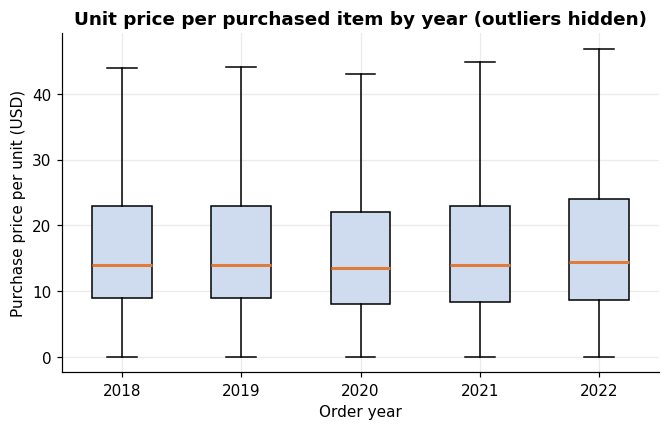

Interpretation (en): Median unit price by year: 2018: $13.99, 2019: $13.99, 2020: $13.47, 2021: $13.99, 2022: $14.40.
Şərh (az):           İllər üzrə median vahid qiymət: 2018: $13.99, 2019: $13.99, 2020: $13.47, 2021: $13.99, 2022: $14.40.


In [18]:
years = sorted(purchases.year.unique())
data = [purchases.loc[purchases.year == y, PRICE].dropna().to_numpy() for y in years]
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(data, showfliers=False, patch_artist=True, boxprops=dict(facecolor="#cfdcef"), medianprops=dict(color=C2, lw=2))
ax.set_xticklabels(years)
ax.set(title="Unit price per purchased item by year (outliers hidden)", xlabel="Order year", ylabel="Purchase price per unit (USD)")
plt.show()
med_by_year = purchases.groupby("year")[PRICE].median()
interp("Median unit price by year: " + ", ".join(f"{y}: ${v:,.2f}" for y, v in med_by_year.items()) + ".",
       "İllər üzrə median vahid qiymət: " + ", ".join(f"{y}: ${v:,.2f}" for y, v in med_by_year.items()) + ".")

**en:** A few users dominate total spend (see Gini and top-1% share above), so a mean-only summary would describe almost nobody. Medians are reported next to means in every later table.

**az:** Bir neçə istifadəçi ümumi xərcə üstünlük təşkil edir (yuxarıdakı Gini və ilk 1% payına bax), ona görə yalnız ortalama demək, demək olar ki, heç kimi təsvir etmir. Sonrakı bütün cədvəllərdə ortalamanın yanında median göstərilir.

## 4. What people buy / Nə alınır

**en:** Category concentration ranked three ways: by distinct users, by item rows and by spend. The three rankings differ on purpose: cheap staples win on users and rows, big-ticket categories win on spend. A Pareto curve shows how fast cumulative spend accrues. ASIN reuse (units from ASINs bought by more than one user) is a crude popularity measure. `Title` is free text and is not parsed beyond the gift-card flag.

**az:** Kateqoriya konsentrasiyası üç üsulla sıralanır: fərqli istifadəçi, məhsul sətri və xərc üzrə. Üç sıralama məqsədli şəkildə fərqlənir: ucuz gündəlik məhsullar istifadəçi və sətir üzrə, bahalı kateqoriyalar xərc üzrə öndədir. Pareto əyrisi yığılmış xərcin nə qədər sürətlə artdığını göstərir. ASIN təkrar istifadəsi (birdən çox istifadəçinin aldığı ASIN-lərdən ədədlər) kobud populyarlıq ölçüsüdür. `Title` sərbəst mətndir və hədiyyə kartı işarəsindən başqa təhlil edilmir.

In [19]:
nocat = purchases["cat"].eq("(missing)")
print(f"uncategorised rows left out of category rankings: {nocat.mean():.1%} of rows, "
      f"{purchases.loc[nocat, 'line_total'].sum() / purchases['line_total'].sum():.1%} of spend")
cat = purchases[~nocat].groupby("cat").agg(users=(ID, "nunique"), rows=(DATE, "size"), units=(QTY, "sum"), spend=("line_total", "sum"))
cat["median_line"] = purchases.groupby("cat")["line_total"].median()
top = pd.concat({"by users": cat.users.nlargest(10).reset_index().cat,
                 "by rows": cat.rows.nlargest(10).reset_index().cat,
                 "by spend": cat.spend.nlargest(10).reset_index().cat}, axis=1)
top.index = top.index + 1
display(top)
overlap = len(set(top["by users"]) & set(top["by rows"]) & set(top["by spend"]))
print(f"categories in all three top-10 lists: {overlap} of 10   |  distinct categories: {len(cat):,}")

uncategorised rows left out of category rankings: 5.2% of rows, 5.8% of spend


,by users,by rows,by spend
1,ABIS_BOOK,ABIS_BOOK,ABIS_BOOK
2,ELECTRONIC_CABLE,PET_FOOD,PET_FOOD
3,CELLULAR_PHONE_CASE,SHIRT,NUTRITIONAL_SUPPLEMENT
4,SHIRT,NUTRITIONAL_SUPPLEMENT,NOTEBOOK_COMPUTER
5,HEADPHONES,ELECTRONIC_CABLE,SHOES
6,HEALTH_PERSONAL_CARE,HEALTH_PERSONAL_CARE,HEADPHONES
7,CHARGING_ADAPTER,MEDICATION,SHIRT
8,SHOES,PANTS,PANTS
9,NUTRITIONAL_SUPPLEMENT,CELLULAR_PHONE_CASE,HEALTH_PERSONAL_CARE
10,PANTS,SKIN_MOISTURIZER,CELLULAR_PHONE


categories in all three top-10 lists: 5 of 10   |  distinct categories: 1,861


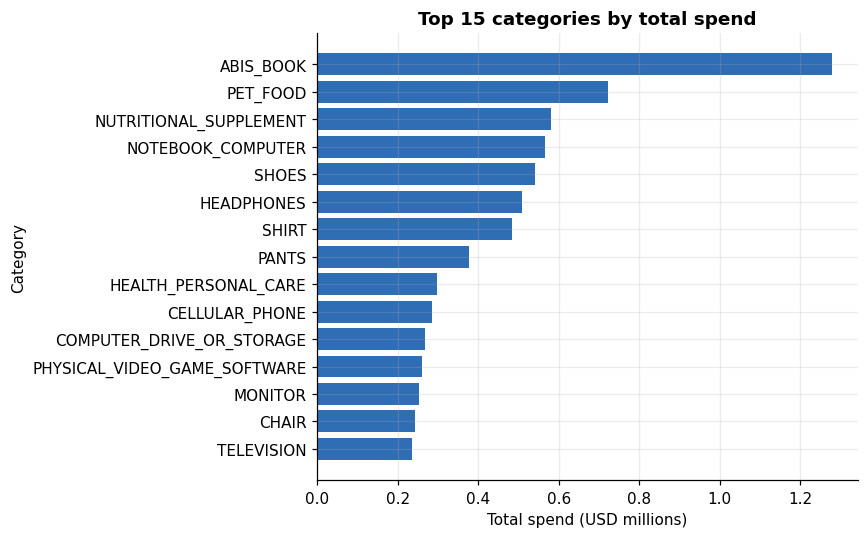

Interpretation (en): 'ABIS_BOOK' leads spend; the top 15 categories hold 18.3% of all spend.
Şərh (az):           Xərcdə 'ABIS_BOOK' öndədir; ilk 15 kateqoriya bütün xərcin 18.3%-ni təşkil edir.


In [20]:
t15 = cat.spend.nlargest(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(t15.index.astype(str), t15.values / 1e6, color=C1)
ax.set(title="Top 15 categories by total spend", xlabel="Total spend (USD millions)", ylabel="Category")
plt.tight_layout(); plt.show()
sh = cat.spend.nlargest(15).sum() / cat.spend.sum()
interp(f"'{t15.index[-1]}' leads spend; the top 15 categories hold {sh:.1%} of all spend.",
       f"Xərcdə '{t15.index[-1]}' öndədir; ilk 15 kateqoriya bütün xərcin {sh:.1%}-ni təşkil edir.")

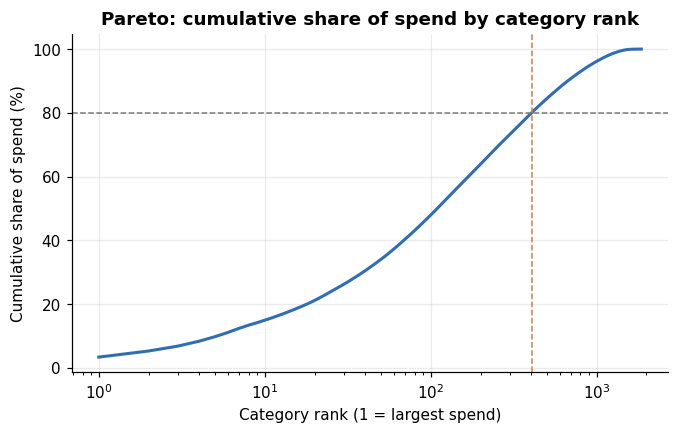

Interpretation (en): 110 categories cover 50% of spend and 406 cover 80%, out of 1,861.
Şərh (az):           1,861 kateqoriyadan 110-i xərcin 50%-ni, 406-i isə 80%-ni əhatə edir.


In [21]:
sp = np.sort(cat.spend.dropna().to_numpy())[::-1]
cshare = np.cumsum(sp) / sp.sum()
k80, k50 = int(np.searchsorted(cshare, 0.8)) + 1, int(np.searchsorted(cshare, 0.5)) + 1
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(cshare) + 1), cshare * 100, color=C1, lw=2)
ax.axhline(80, color=C3, ls="--", lw=1); ax.axvline(k80, color=C2, ls="--", lw=1)
ax.set(title="Pareto: cumulative share of spend by category rank", xlabel="Category rank (1 = largest spend)",
       ylabel="Cumulative share of spend (%)", xscale="log"); plt.show()
interp(f"{k50} categories cover 50% of spend and {k80} cover 80%, out of {len(cshare):,}.",
       f"{len(cshare):,} kateqoriyadan {k50}-i xərcin 50%-ni, {k80}-i isə 80%-ni əhatə edir.")

In [22]:
asin_users = purchases.dropna(subset=[ASIN]).groupby(ASIN)[ID].nunique()
shared_asins = asin_users[asin_users > 1].index
units_known = purchases.dropna(subset=[ASIN])
share_units_shared = units_known.loc[units_known[ASIN].isin(shared_asins), QTY].sum() / units_known[QTY].sum()
print(f"distinct ASINs: {len(asin_users):,} | bought by >1 user: {len(shared_asins):,} ({len(shared_asins)/len(asin_users):.1%})")
print(f"share of units from ASINs bought by more than one user: {share_units_shared:.1%}")
print("most widely bought ASINs (users):"); display(asin_users.nlargest(5).rename("users").to_frame().join(
    purchases.drop_duplicates(ASIN).set_index(ASIN)[[TITLE, "cat"]]))

distinct ASINs: 886,631 | bought by >1 user: 182,462 (20.6%)
share of units from ASINs bought by more than one user: 55.9%
most widely bought ASINs (users):


,users,Title,cat
ASIN/ISBN (Product Code),,,
B07FZ8S74R,353,"Echo Dot (3rd Gen, 2018 release) - Smart speak...",DIGITAL_DEVICE_3
B079QHML21,350,Fire TV Stick 4K streaming device with Alexa V...,DIGITAL_DEVICE_4
B00LH3DMUO,349,Amazon Basics 36 Pack AAA High-Performance Alk...,BATTERY
B00MNV8E0C,291,Amazon Basics 48 Pack AA High-Performance Alka...,BATTERY
B01MZEEFNX,290,"Amazon Smart Plug, works with Alexa – A Certif...",DIGITAL_DEVICE_3_ACCESSORY


**en:** Reading: the three category rankings do not match, and spend is far more concentrated than the number of buyers suggests. ASIN reuse is only a crude popularity proxy: a product bought by one user in this sample may still be popular on Amazon.

**az:** Oxunuş: üç kateqoriya sıralaması üst-üstə düşmür və xərc alıcıların sayından göründüyündən daha çox konsentrasiya olunub. ASIN təkrarı yalnız kobud populyarlıq göstəricisidir: bu nümunədə bir istifadəçinin aldığı məhsul Amazon-da yenə populyar ola bilər.

## 5. Seasonality / Mövsümilik

**en:** Monthly spend and item counts with gift cards excluded, next to a gift-card-only series (the December spike should appear there). Then month-of-year profiles for a boots-type category, a sandals-type category and an evergreen control, and a year by month heatmap. A simple numpy check separates trend from season. This is **not** compared to Amazon's reported revenue: the paper's r = 0.978 is against Amazon North America net sales, which needs an external series that is not local.

**az:** Hədiyyə kartları xaric aylıq xərc və məhsul sayı, yanında yalnız hədiyyə kartlarından ibarət seriya (dekabr sıçrayışı orada görünməlidir). Sonra çəkmə tipli kateqoriya, sandal tipli kateqoriya və daimi tələbatlı nəzarət kateqoriyası üçün ilin ayları üzrə profillər və il x ay istilik xəritəsi. Sadə numpy yoxlaması trend və mövsümü ayırır. Amazon-un rəsmi gəliri ilə **müqayisə edilmir**: məqalədəki r = 0.978 Amazon North America xalis satışları ilədir, bu isə lokal olmayan xarici seriya tələb edir.

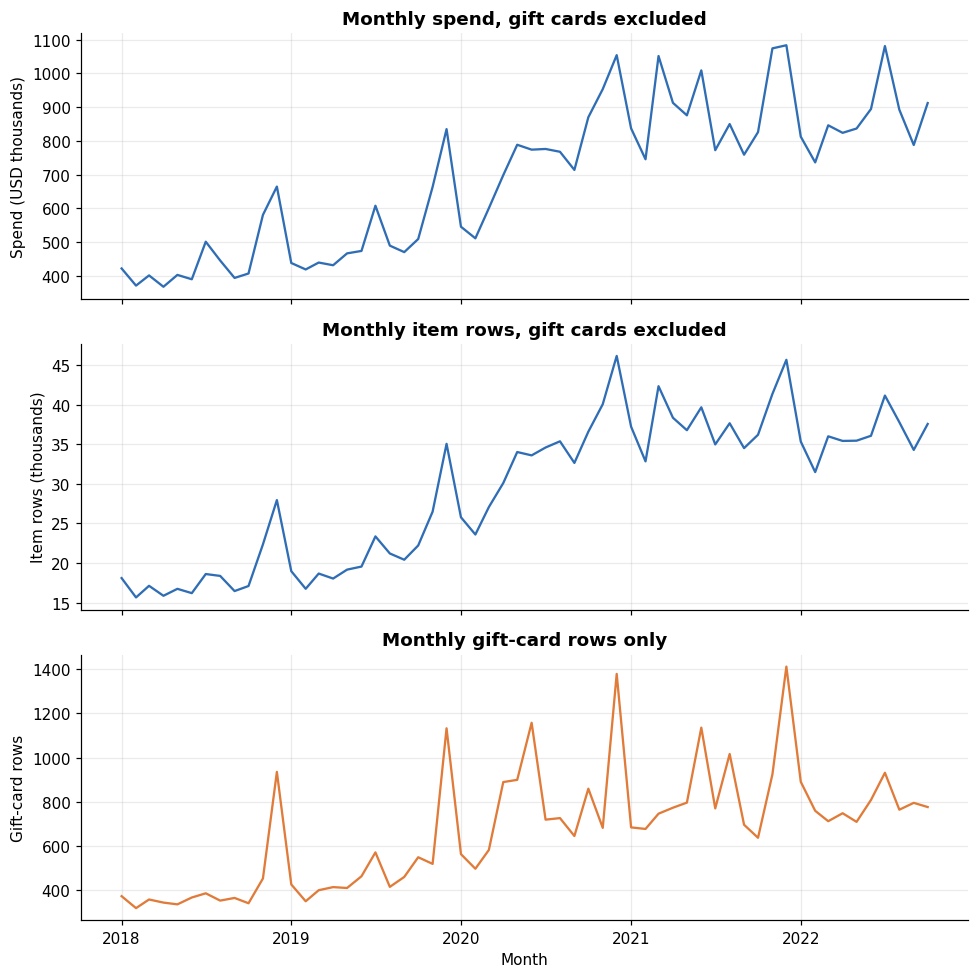

Interpretation (en): December gift-card volume is 1.79x an average month versus 1.31x for all other items; peak gift-card month is 12.
Şərh (az):           Dekabrda hədiyyə kartı həcmi orta aydan 1.79 dəfə, digər məhsullarda isə 1.31 dəfə yüksəkdir; hədiyyə kartlarında pik ay: 12.


In [23]:
monthly = purchases.groupby("month").agg(spend=("line_total", "sum"), items=(DATE, "size"))
gc_monthly = purchases_gc.groupby("month").agg(rows=(DATE, "size"), spend=("line_total", "sum"))
full = pd.date_range("2018-01-01", "2022-10-01", freq="MS")
monthly, gc_monthly = monthly.reindex(full), gc_monthly.reindex(full).fillna(0)

def moy_index(s):
    """Mean by calendar month divided by the overall mean (1.0 = average month); handles unequal year counts."""
    g = s.groupby(s.index.month).mean()
    return g / g.mean()

fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
axes[0].plot(monthly.index, monthly.spend / 1e3, color=C1); axes[0].set(title="Monthly spend, gift cards excluded", ylabel="Spend (USD thousands)")
axes[1].plot(monthly.index, monthly["items"] / 1e3, color=C1); axes[1].set(title="Monthly item rows, gift cards excluded", ylabel="Item rows (thousands)")
axes[2].plot(gc_monthly.index, gc_monthly.rows, color=C2); axes[2].set(title="Monthly gift-card rows only", ylabel="Gift-card rows", xlabel="Month")
plt.tight_layout(); plt.show()
gc_idx, all_idx = moy_index(gc_monthly.rows), moy_index(monthly["items"])
interp(f"December gift-card volume is {gc_idx[12]:.2f}x an average month versus {all_idx[12]:.2f}x for all other items; peak gift-card month is {gc_idx.idxmax()}.",
       f"Dekabrda hədiyyə kartı həcmi orta aydan {gc_idx[12]:.2f} dəfə, digər məhsullarda isə {all_idx[12]:.2f} dəfə yüksəkdir; hədiyyə kartlarında pik ay: {gc_idx.idxmax()}.")

chosen: [('BOOT', 'boots-type'), ('SANDAL', 'sandals-type'), ('NUTRITIONAL_SUPPLEMENT', 'evergreen control')]


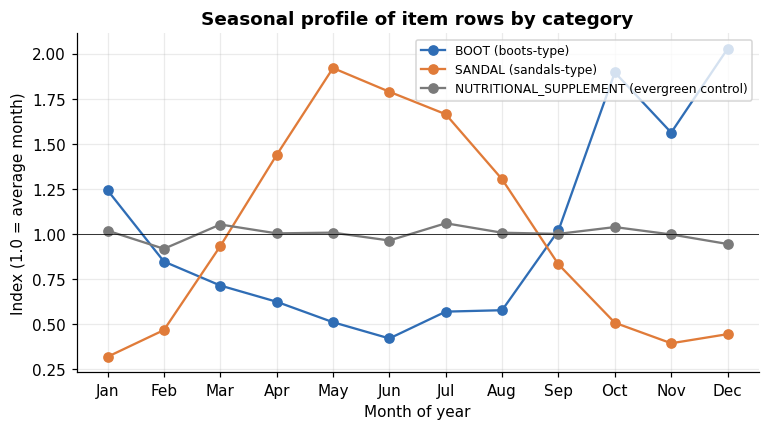

Interpretation (en): BOOT peaks in month 12 (2.03x); SANDAL peaks in month 5 (1.92x); NUTRITIONAL_SUPPLEMENT peaks in month 7 (1.06x).
Şərh (az):           BOOT: pik ay 12 (2.03x); SANDAL: pik ay 5 (1.92x); NUTRITIONAL_SUPPLEMENT: pik ay 7 (1.06x).


In [24]:
cats_str = purchases["cat"].astype(str)
def pick(pattern, exclude=()):
    sub = purchases[cats_str.str.contains(pattern, case=False, regex=True) & ~purchases["cat"].isin(exclude)]
    return sub["cat"].value_counts().index[0] if len(sub) else None

boot, sandal = pick("BOOT"), pick("SANDAL")
cat_month = purchases.groupby(["cat", "month"]).size().unstack(0).reindex(full).fillna(0)
cand = [c for c in cat.users.nlargest(30).index if c not in (boot, sandal, "(missing)")]
# evergreen control = most calendar-flat of the 30 largest categories (lowest spread of month-of-year index)
control = min(cand, key=lambda c: moy_index(cat_month[c]).std())
chosen = [(c, lab, col) for c, lab, col in [(boot, "boots-type", C1), (sandal, "sandals-type", C2), (control, "evergreen control", C3)] if c]
print("chosen:", [(c, lab) for c, lab, _ in chosen])

fig, ax = plt.subplots(figsize=(8, 4))
for c, lab, col in chosen:
    ax.plot(range(1, 13), moy_index(cat_month[c]).values, marker="o", color=col, label=f"{c} ({lab})")
ax.axhline(1, color="k", lw=0.5)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set(title="Seasonal profile of item rows by category", xlabel="Month of year", ylabel="Index (1.0 = average month)"); ax.legend(fontsize=8); plt.show()
parts_en = [f"{c} peaks in month {moy_index(cat_month[c]).idxmax()} ({moy_index(cat_month[c]).max():.2f}x)" for c, _, _ in chosen]
interp("; ".join(parts_en) + ".", "; ".join(f"{c}: pik ay {moy_index(cat_month[c]).idxmax()} ({moy_index(cat_month[c]).max():.2f}x)" for c, _, _ in chosen) + ".")

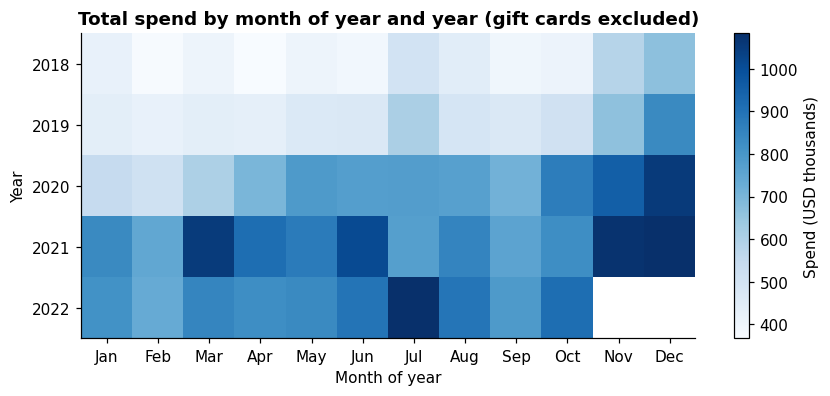

Interpretation (en): Darker cells mark high-spend months; the grid ends in October 2022 (Nov/Dec 2022 are blank by design); the strongest year is 2021.
Şərh (az):           Tünd xanalar yüksək xərcli aylardır; cədvəl 2022-ci ilin oktyabrında bitir (2022 Noyabr/Dekabr qəsdən boşdur); ən güclü il 2021-dir.


In [25]:
heat = purchases.pivot_table(index="year", columns="moy", values="line_total", aggfunc="sum") / 1e3
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(heat.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(12)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(heat.index))); ax.set_yticklabels(heat.index)
ax.grid(False); fig.colorbar(im, ax=ax, label="Spend (USD thousands)")
ax.set(title="Total spend by month of year and year (gift cards excluded)", xlabel="Month of year", ylabel="Year"); plt.show()
yr_tot = heat.sum(axis=1)
interp(f"Darker cells mark high-spend months; the grid ends in October 2022 (Nov/Dec 2022 are blank by design); the strongest year is {int(yr_tot.idxmax())}.",
       f"Tünd xanalar yüksək xərcli aylardır; cədvəl 2022-ci ilin oktyabrında bitir (2022 Noyabr/Dekabr qəsdən boşdur); ən güclü il {int(yr_tot.idxmax())}-dir.")

In [26]:
# Trend versus season on monthly total spend
y = monthly.spend.to_numpy(); t = np.arange(len(y))
r_trend = np.corrcoef(t, y)[0, 1]
season_fit = pd.Series(y, index=full).groupby(full.month).transform("mean").to_numpy()
r2_season = 1 - ((y - season_fit) ** 2).sum() / ((y - y.mean()) ** 2).sum()
slope, intercept = np.polyfit(t, y, 1)
r2_trend = r_trend ** 2
print(f"corr(month index, monthly spend) r = {r_trend:.2f}  (R2 {r2_trend:.2f})")
print(f"calendar-month means alone explain R2 = {r2_season:.2f} of monthly variance; linear trend {slope:+,.0f} USD per month")
print("Not compared with Amazon revenue; that needs an external series.")

corr(month index, monthly spend) r = 0.85  (R2 0.73)
calendar-month means alone explain R2 = 0.16 of monthly variance; linear trend +11,030 USD per month
Not compared with Amazon revenue; that needs an external series.


## 6. Who spends / Kim xərcləyir

**en:** Survey demographics (gender, age, household income, education) against the user spend table. Spend is **annualized by months observed** (first to last order month in the window) so a user who stopped exporting in 2019 is not labeled low-spending. Users observed for fewer than 6 months are excluded from annualized figures because 12/1 scaling is unstable. The survey's age groups are collapsed to 18-34, 35-54, 55+. Cells with n below 30 are shown but **not interpreted**. Race and health fields are left out on purpose; the sample already skews towards women and higher education.

**az:** Survey demoqrafikası (cins, yaş, ev təsərrüfatı gəliri, təhsil) istifadəçi xərc cədvəli ilə müqayisədə. Xərc **müşahidə olunan ayların sayına görə illiklənir** (pəncərədə ilk və son sifariş ayı arası), beləliklə 2019-da ixracı dayandıran istifadəçi "az xərcləyən" sayılmır. 6 aydan az müşahidə olunanlar illik göstəricilərdən çıxarılır, çünki 12/1 miqyaslaması qeyri-sabitdir. Yaş qrupları 18-34, 35-54, 55+ şəklində birləşdirilir. n-i 30-dan kiçik xanalar göstərilir, lakin **şərh edilmir**. Irq və sağlamlıq sahələri qəsdən kənarda saxlanılır; nümunə artıq qadınlara və ali təhsilliyə meyillidir.

In [27]:
MIN_MONTHS, MIN_N = 6, 30
u = users.copy()
u["months_observed"] = (u.last_month.dt.year - u.first_month.dt.year) * 12 + (u.last_month.dt.month - u.first_month.dt.month) + 1
u["annual_spend"] = u.spend / u.months_observed * 12
u = u.join(survey.set_index(ID)[DEMO])
print(f"users: {len(u):,} | observed >= {MIN_MONTHS} months: {(u.months_observed >= MIN_MONTHS).sum():,} (rest excluded from annualized stats)")
ua = u[u.months_observed >= MIN_MONTHS].copy()

AGE = {"18 - 24 years": "18-34", "25 - 34 years": "18-34", "35 - 44 years": "35-54", "45 - 54 years": "35-54",
       "55 - 64 years": "55+", "65 and older": "55+"}
ua["age"] = ua["Q-demos-age"].map(AGE)
ua["income"] = ua["Q-demos-income"]
ua["gender"] = ua["Q-demos-gender"]
ua["education"] = ua["Q-demos-education"].map(lambda s: "Graduate/professional" if str(s).startswith("Graduate") else s)

ORD = {"age": ["18-34", "35-54", "55+"],
       "income": ["Less than $25,000", "$25,000 - $49,999", "$50,000 - $74,999", "$75,000 - $99,999",
                  "$100,000 - $149,999", "$150,000 or more", "Prefer not to say"],
       "gender": ["Female", "Male", "Other", "Prefer not to say"],
       "education": ["Some high school or less", "High school diploma or GED", "Bachelor's degree", "Graduate/professional", "Prefer not to say"]}

def summarize(col):
    t = ua.groupby(col).agg(n=("annual_spend", "size"), median_annual=("annual_spend", "median"),
                            mean_annual=("annual_spend", "mean"), total_spend=("spend", "sum"))
    t["share_of_total_spend_%"] = t.total_spend / ua.spend.sum() * 100
    t = t.reindex([o for o in ORD[col] if o in t.index])
    t["note"] = np.where(t.n < MIN_N, f"n<{MIN_N}: not interpreted", "")
    return t.drop(columns="total_spend").round(1)

tables = {c: summarize(c) for c in ORD}
for c, t in tables.items():
    print(f"\n=== {c}"); display(t)

users: 5,014 | observed >= 6 months: 4,975 (rest excluded from annualized stats)

=== age


,n,median_annual,mean_annual,share_of_total_spend_%,note
age,,,,,
18-34,2544,957.3,1466.3,41.3,
35-54,1907,1493.3,2144.3,47.0,
55+,524,1333.9,1911.8,11.7,



=== income


,n,median_annual,mean_annual,share_of_total_spend_%,note
income,,,,,
"Less than $25,000",680,770.0,1144.7,8.4,
"$25,000 - $49,999",1180,924.4,1359.6,17.8,
"$50,000 - $74,999",1052,1163.1,1670.8,19.7,
"$75,000 - $99,999",750,1444.0,1915.0,16.4,
"$100,000 - $149,999",781,1678.5,2403.3,21.8,
"$150,000 or more",458,2149.5,2800.0,14.9,
Prefer not to say,74,699.0,1152.5,0.9,



=== gender


,n,median_annual,mean_annual,share_of_total_spend_%,note
gender,,,,,
Female,2568,1242.9,1840.6,53.9,
Male,2280,1127.8,1728.3,44.4,
Other,116,844.9,1269.8,1.7,
Prefer not to say,11,582.8,614.3,0.1,n<30: not interpreted



=== education


,n,median_annual,mean_annual,share_of_total_spend_%,note
education,,,,,
Some high school or less,45,904.7,1224.6,0.6,
High school diploma or GED,1837,970.2,1529.0,31.0,
Bachelor's degree,2199,1234.6,1801.2,45.2,
Graduate/professional,862,1653.4,2247.3,22.5,
Prefer not to say,32,1012.4,1857.0,0.6,


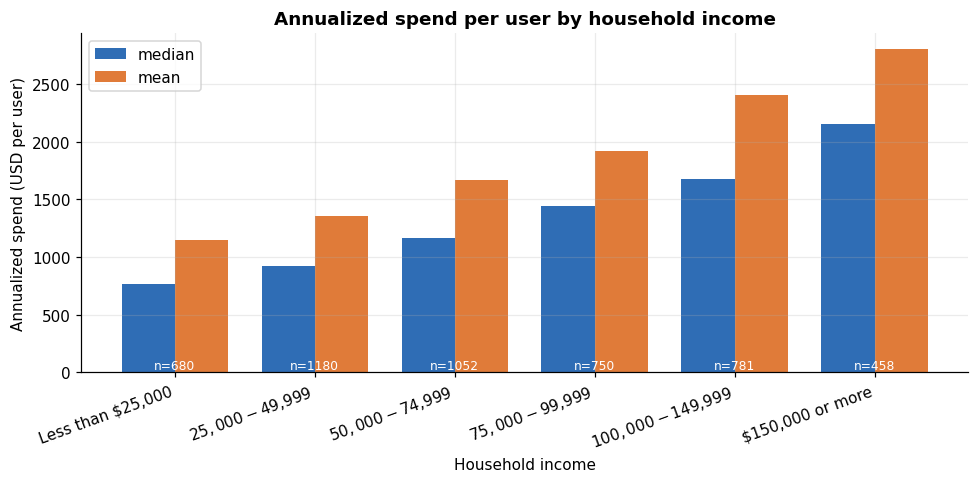

Interpretation (en): median annualized spend rises in 5 of 5 income steps (corr with income level 0.99): $770 at the lowest to $2,150 at the highest income band.
Şərh (az):           illik xərc medianı 5 gəlir addımının 5-də artır (gəlir səviyyəsi ilə korrelyasiya 0.99): ən aşağıdan ən yuxarı qrupa $770 -> $2,150.


In [28]:
inc = tables["income"]; inc_plot = inc.drop("Prefer not to say", errors="ignore")
x = np.arange(len(inc_plot)); w = 0.38
ok = inc_plot.n >= MIN_N
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w/2, inc_plot.median_annual.where(ok), w, color=C1, label="median")
ax.bar(x + w/2, inc_plot.mean_annual.where(ok), w, color=C2, label="mean")
ax.set_xticks(x); ax.set_xticklabels(inc_plot.index, rotation=20, ha="right")
for i, n in enumerate(inc_plot.n): ax.text(i, 0, f"n={n}", ha="center", va="bottom", fontsize=8, color="white" if ok.iloc[i] else "k")
ax.set(title="Annualized spend per user by household income", xlabel="Household income", ylabel="Annualized spend (USD per user)"); ax.legend(); plt.tight_layout(); plt.show()
med = inc_plot.median_annual[ok]
rho = np.corrcoef(np.arange(len(med)), med.to_numpy())[0, 1]
ups = int((np.diff(med.to_numpy()) > 0).sum())
income_gradient = (f"median annualized spend rises in {ups} of {len(med)-1} income steps (corr with income level {rho:.2f}): "
                   f"${med.iloc[0]:,.0f} at the lowest to ${med.iloc[-1]:,.0f} at the highest income band")
interp(income_gradient + ".", f"illik xərc medianı {len(med)-1} gəlir addımının {ups}-də artır (gəlir səviyyəsi ilə korrelyasiya {rho:.2f}): ən aşağıdan ən yuxarı qrupa ${med.iloc[0]:,.0f} -> ${med.iloc[-1]:,.0f}.")

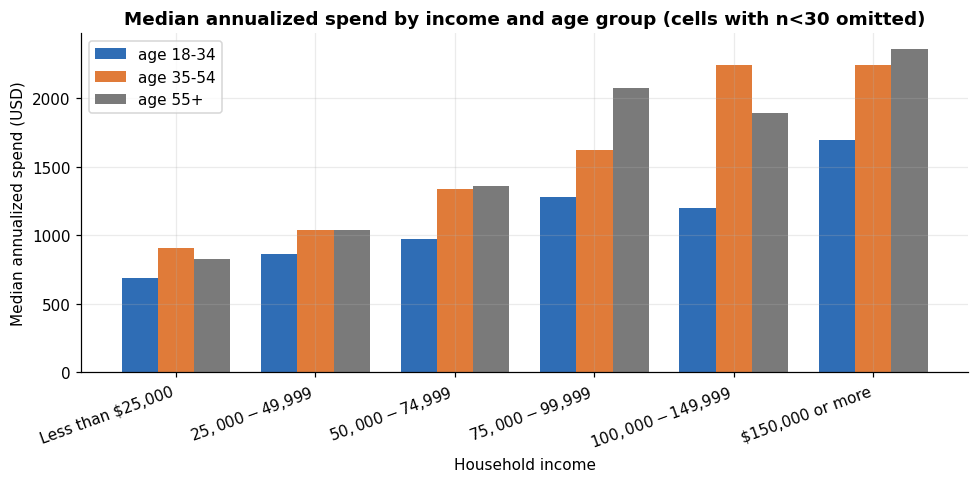

n per income x age cell (cells below 30 are not interpreted):


age,18-34,35-54,55+
income,,,
"Less than $25,000",409,191,80
"$25,000 - $49,999",666,375,139
"$50,000 - $74,999",536,430,86
"$75,000 - $99,999",373,296,81
"$100,000 - $149,999",327,367,87
"$150,000 or more",179,233,46


Interpretation (en): By age group the median annualized spend is 18-34: $957 (n=2544), 35-54: $1,493 (n=1907), 55+: $1,334 (n=524).
Şərh (az):           Yaş qrupları üzrə illik xərc medianı: 18-34: $957 (n=2544), 35-54: $1,493 (n=1907), 55+: $1,334 (n=524).


In [29]:
inc_order = [o for o in ORD["income"] if o != "Prefer not to say"]
cell_n = ua[ua.income.isin(inc_order)].pivot_table(index="income", columns="age", values="annual_spend", aggfunc="size").reindex(inc_order)[ORD["age"]]
cell_med = ua[ua.income.isin(inc_order)].pivot_table(index="income", columns="age", values="annual_spend", aggfunc="median").reindex(inc_order)[ORD["age"]]
cell_med_plot = cell_med.where(cell_n >= MIN_N)

fig, ax = plt.subplots(figsize=(9, 4.5)); x = np.arange(len(inc_order)); w = 0.26
for i, (a, col) in enumerate(zip(ORD["age"], [C1, C2, C3])):
    ax.bar(x + (i - 1) * w, cell_med_plot[a], w, color=col, label=f"age {a}")
ax.set_xticks(x); ax.set_xticklabels(inc_order, rotation=20, ha="right")
ax.set(title="Median annualized spend by income and age group (cells with n<30 omitted)", xlabel="Household income", ylabel="Median annualized spend (USD)"); ax.legend(); plt.tight_layout(); plt.show()
print("n per income x age cell (cells below 30 are not interpreted):"); display(cell_n)
age_t = tables["age"]
interp("By age group the median annualized spend is " + ", ".join(f"{a}: ${age_t.loc[a,'median_annual']:,.0f} (n={age_t.loc[a,'n']})" for a in age_t.index) + ".",
       "Yaş qrupları üzrə illik xərc medianı: " + ", ".join(f"{a}: ${age_t.loc[a,'median_annual']:,.0f} (n={age_t.loc[a,'n']})" for a in age_t.index) + ".")

## 7. Geography / Coğrafiya

**en:** The state used is the **shipping state**, not the survey residence; they differ when a gift ships elsewhere. Per state: users, item rows, total spend, median user spend and top category by spend. A choropleth needs a map library and is out of scope. Instead: a ranked bar of the top 15 states by median user spend (n annotated, states with fewer than 30 users excluded) and a users-versus-total-spend scatter so large states are not mistaken for rich ones.

**az:** İstifadə olunan ştat **çatdırılma ştatıdır**, survey-dəki yaşayış ştatı deyil; hədiyyə başqa yerə göndəriləndə bunlar fərqlənir. Hər ştat üçün: istifadəçi sayı, məhsul sətirləri, ümumi xərc, istifadəçi xərcinin medianı və xərc üzrə ən böyük kateqoriya. Xoropleth xəritə kitabxanası tələb edir və əhatədən kənardır. Əvəzində: istifadəçi xərci medianı üzrə ilk 15 ştatın sıralı sütun qrafiki (n qeyd olunub, 30-dan az istifadəçisi olan ştatlar çıxarılıb) və istifadəçi sayı - ümumi xərc səpələnmə qrafiki; böyük ştatlar "zəngin" sanılmasın deyə.

In [30]:
MIN_STATE_N = 30
geo = purchases[~purchases.state_code.isin(["MISSING", "UNMAPPED"])]
user_state = geo.groupby([ID, "state_code"]).line_total.sum().reset_index()
st = geo.groupby("state_code").agg(users=(ID, "nunique"), items=(DATE, "size"), total_spend=("line_total", "sum"))
st["median_user_spend"] = user_state.groupby("state_code").line_total.median()
st["mean_user_spend"] = user_state.groupby("state_code").line_total.mean()
sc = geo.groupby(["state_code", "cat"]).line_total.sum()
st["top_category"] = sc.groupby(level=0).idxmax().map(lambda t: t[1])
st = st.sort_values("total_spend", ascending=False)
print(f"rows with a usable shipping state: {len(geo):,} of {len(purchases):,} ({len(geo)/len(purchases):.1%}); states/territories: {len(st)}")
display(st.head(15).round(0))

rows with a usable shipping state: 1,650,833 of 1,698,208 (97.2%); states/territories: 52


,users,items,total_spend,median_user_spend,mean_user_spend,top_category
state_code,,,,,,
CA,903,167267,4048332.0,1118.0,4483.0,(missing)
TX,720,127210,3027796.0,921.0,4205.0,(missing)
FL,739,103294,2477963.0,506.0,3353.0,(missing)
NY,584,96506,2206815.0,852.0,3779.0,(missing)
PA,517,91519,2060344.0,1088.0,3985.0,(missing)
OH,409,81391,1832821.0,1128.0,4481.0,(missing)
IL,433,67261,1630755.0,702.0,3766.0,(missing)
NC,382,66165,1568393.0,650.0,4106.0,(missing)
MI,306,56260,1304013.0,1352.0,4261.0,(missing)


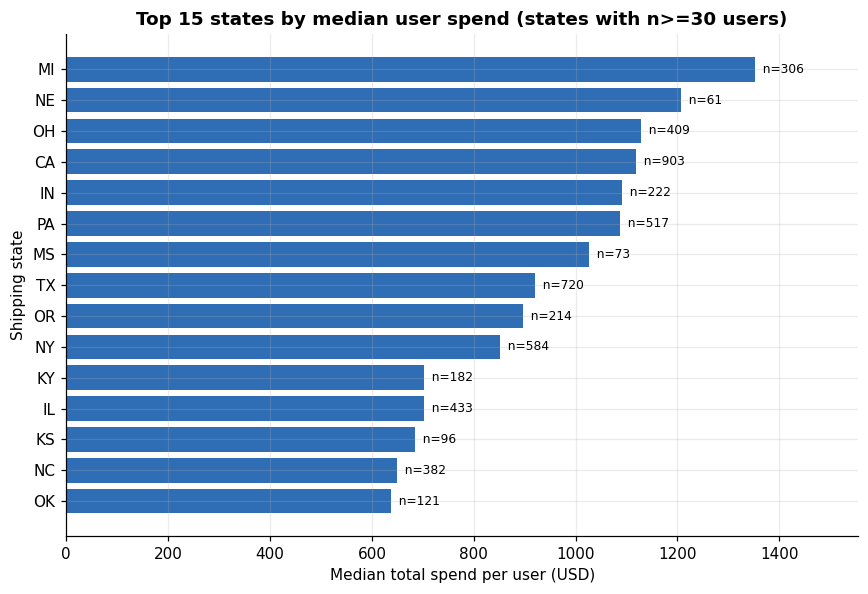

Interpretation (en): MI has the highest median ($1,352); the top-15 range is only 2.12x, so differences between states are modest and n is small.
Şərh (az):           Ən yüksək median MI ştatındadır ($1,352); ilk 15 arasında fərq cəmi 2.12 dəfədir, yəni ştatlar arası fərqlər azdır və n kiçikdir.


In [31]:
rk = st[st.users >= MIN_STATE_N].nlargest(15, "median_user_spend").sort_values("median_user_spend")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(rk.index, rk.median_user_spend, color=C1)
for i, (idx, r) in enumerate(rk.iterrows()): ax.text(r.median_user_spend, i, f"  n={int(r.users)}", va="center", fontsize=8)
ax.set(title=f"Top 15 states by median user spend (states with n>={MIN_STATE_N} users)", xlabel="Median total spend per user (USD)", ylabel="Shipping state")
ax.set_xlim(0, rk.median_user_spend.max() * 1.15); plt.tight_layout(); plt.show()
spread = rk.median_user_spend.max() / rk.median_user_spend.min()
interp(f"{rk.index[-1]} has the highest median (${rk.median_user_spend.iloc[-1]:,.0f}); the top-15 range is only {spread:.2f}x, so differences between states are modest and n is small.",
       f"Ən yüksək median {rk.index[-1]} ştatındadır (${rk.median_user_spend.iloc[-1]:,.0f}); ilk 15 arasında fərq cəmi {spread:.2f} dəfədir, yəni ştatlar arası fərqlər azdır və n kiçikdir.")

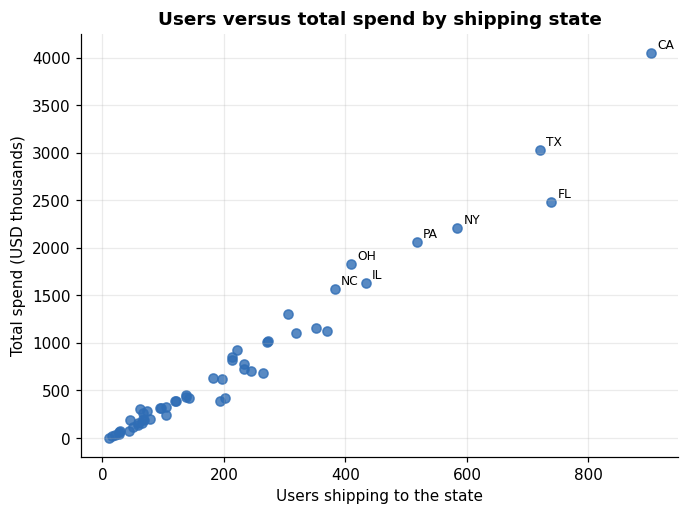

corr(state user count, state total spend) = 0.984
Interpretation (en): Correlation is r = 0.98: total state spend mostly tracks how many users ship there, so large states are not richer states.
Şərh (az):           Korrelyasiya r = 0.98: ştatın ümumi xərci əsasən ora çatdırılan istifadəçi sayını izləyir, yəni böyük ştatlar daha zəngin ştatlar demək deyil.


In [32]:
r_state = np.corrcoef(st.users.to_numpy(float), st.total_spend.to_numpy(float))[0, 1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(st.users, st.total_spend / 1e3, color=C1, alpha=0.8)
for idx, r in st.nlargest(8, "total_spend").iterrows(): ax.annotate(idx, (r.users, r.total_spend / 1e3), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set(title="Users versus total spend by shipping state", xlabel="Users shipping to the state", ylabel="Total spend (USD thousands)"); plt.show()
print(f"corr(state user count, state total spend) = {r_state:.3f}")
interp(f"Correlation is r = {r_state:.2f}: total state spend mostly tracks how many users ship there, so large states are not richer states.",
       f"Korrelyasiya r = {r_state:.2f}: ştatın ümumi xərci əsasən ora çatdırılan istifadəçi sayını izləyir, yəni böyük ştatlar daha zəngin ştatlar demək deyil.")

In [33]:
# Shipping versus survey residence
res = purchases["Q-demos-state"].astype("string").str.upper().map(NAME2CODE)
both = purchases.state_code.isin(VALID_CODES) & res.notna()
mismatch = (purchases.state_code[both] != res[both]).mean()
print(f"item rows shipped to a different state than the buyer's survey residence: {mismatch:.1%} (of {both.sum():,} comparable rows)")

item rows shipped to a different state than the buyer's survey residence: 9.0% (of 1,650,123 comparable rows)


## Key takeaways / Əsas nəticələr

In [34]:
cat_top = cat.spend.idxmax()
print(f"""KEY TAKEAWAYS / ƏSAS NƏTİCƏLƏR

1. Skew / Əyrilik
   en: Spend is highly skewed: Gini {gini:.2f}, top 1% of users = {top1:.0%} of spend, mean ${spend.mean():,.0f} vs median ${np.median(spend):,.0f}.
   az: Xərc güclü əyridir: Gini {gini:.2f}, ilk 1% istifadəçi xərcin {top1:.0%}-i, ortalama ${spend.mean():,.0f}, median ${np.median(spend):,.0f}.

2. Category concentration / Kateqoriya konsentrasiyası
   en: {k80} of {len(cshare):,} categories cover 80% of spend; '{cat_top}' leads spend, and the user, row and spend rankings differ.
   az: {len(cshare):,} kateqoriyadan {k80}-i xərcin 80%-ni əhatə edir; xərcdə '{cat_top}' öndədir, istifadəçi, sətir və xərc sıralamaları fərqlənir.

3. December gift-card seasonality / Dekabr hədiyyə kartı mövsümiliyi
   en: December gift-card volume is {gc_idx[12]:.2f}x an average month (other items: {all_idx[12]:.2f}x).
   az: Dekabrda hədiyyə kartı həcmi orta aydan {gc_idx[12]:.2f} dəfə yüksəkdir (digər məhsullar: {all_idx[12]:.2f}x).

4. Income gradient / Gəlir qradiyenti
   en: After annualizing, {income_gradient}.
   az: İllikləşdirmədən sonra gəlir qradiyenti: median {ups}/{len(med)-1} addımda artır, ən aşağı ${med.iloc[0]:,.0f}, ən yuxarı ${med.iloc[-1]:,.0f}.

5. Shipping vs residence / Çatdırılma və yaşayış
   en: Geography uses shipping state; {mismatch:.0%} of comparable item rows ship outside the buyer's home state, and state spend tracks user count (r = {r_state:.2f}).
   az: Coğrafiya çatdırılma ştatına əsaslanır; müqayisə olunan sətirlərin {mismatch:.0%}-i alıcının öz ştatından kənara göndərilir və ştat xərci istifadəçi sayını izləyir (r = {r_state:.2f}).
""")

KEY TAKEAWAYS / ƏSAS NƏTİCƏLƏR

1. Skew / Əyrilik
   en: Spend is highly skewed: Gini 0.53, top 1% of users = 7% of spend, mean $7,989 vs median $5,166.
   az: Xərc güclü əyridir: Gini 0.53, ilk 1% istifadəçi xərcin 7%-i, ortalama $7,989, median $5,166.

2. Category concentration / Kateqoriya konsentrasiyası
   en: 406 of 1,861 categories cover 80% of spend; 'ABIS_BOOK' leads spend, and the user, row and spend rankings differ.
   az: 1,861 kateqoriyadan 406-i xərcin 80%-ni əhatə edir; xərcdə 'ABIS_BOOK' öndədir, istifadəçi, sətir və xərc sıralamaları fərqlənir.

3. December gift-card seasonality / Dekabr hədiyyə kartı mövsümiliyi
   en: December gift-card volume is 1.79x an average month (other items: 1.31x).
   az: Dekabrda hədiyyə kartı həcmi orta aydan 1.79 dəfə yüksəkdir (digər məhsullar: 1.31x).

4. Income gradient / Gəlir qradiyenti
   en: After annualizing, median annualized spend rises in 5 of 5 income steps (corr with income level 0.99): $770 at the lowest to $2,150 at the hig

**en:** Caveats: the sample is volunteers who shared their Amazon history, skewed toward women and higher education; no order id exists; results describe this sample, not all US Amazon shoppers.

**az:** Qeydlər: nümunə Amazon tarixçəsini paylaşan könüllülərdir, qadınlara və ali təhsilə meyillidir; sifariş identifikatoru yoxdur; nəticələr bu nümunəni təsvir edir, bütün ABŞ Amazon alıcılarını yox.